# Predictive Customer Lifetime Value: Comparing Statistical and Machine Learning Models
**Notebook 2 (Version 6) | Marketing Data Science | Google Colab**

This reproducible experiment forecasts **2025 purchases and customer contribution** for the 2,000 synthetic customers created in Notebook 1. We compare six approaches:

| Family | Model | What it forecasts directly |
|---|---|---|
| Naive baseline | Run-rate (lifetime): each customer's historical annual average | Transactions, contribution |
| Naive baseline | Run-rate (last 365 days): each customer's 2024 totals | Transactions, contribution |
| Probabilistic | **BG/NBD + Gamma-Gamma** | Purchase occasions, then contribution per occasion |
| Probabilistic | **Pareto/NBD + Gamma-Gamma** | Purchase occasions, then contribution per occasion |
| Machine learning | Random forest | Transactions, contribution |
| Machine learning | Histogram gradient boosting | Transactions, contribution |

**Protocol.** Observation through **2024-12-31**, forecast **2025-01-01 to 2025-12-31**, same 2,000 existing customers throughout. Simulator ground truth is evaluation-only. Every modeling setting in this version was fixed **before** fitting (Section 1), then the entire comparison is **replicated on 20 fresh synthetic customer bases** that nobody has looked at (Section 13).

**Important:** these data are synthetic educational examples, not industry benchmarks. This notebook evaluates forecasts, not causal effects.

### What changed in Version 6, and why

Earlier versions used `penalizer_coef=1.0` for BG/NBD and `0.10` for Gamma-Gamma. Investigating those choices turned up three problems:

1. **The BG/NBD "NaN" predictions were a numerical bug in `lifetimes`, not a model failure.** For customers with no repeat purchases, the library takes the logarithm of a hypergeometric term that can legitimately be negative when the fitted `a + b < 1`. Section 5 computes the same published equation (Fader, Hardie, and Lee 2005, eq. 10) without the logarithm. It matches `lifetimes` to machine precision wherever `lifetimes` returns a number, and it is finite everywhere else.
2. **The penalizers were changing the answer.** Heavy regularization shrank the BG/NBD parameters and inflated the 2025 forecast, and it pushed the Gamma-Gamma shape parameter `q` below 1 (which implies an infinite population mean). With no penalty, `q` is well above 1.
3. **Pareto/NBD was missing.** The simulator lets customers drop out at the end of any month, buying or not. That matches Pareto/NBD's assumption better than BG/NBD's, where dropout can only happen right after a purchase. Comparing the two is the clearest way to show why model assumptions matter.

Version 6 therefore uses the **library default of no penalty** for all three probabilistic models, adds Pareto/NBD, removes the post-hoc "historical monetary" hybrid, and applies Gamma-Gamma's own population mean to zero-repeat customers instead of an ad hoc fallback. **Disclosure:** the primary seed's 2025 holdout was viewed while developing earlier versions, so the primary results in Sections 7 to 12 are not a blind test. The replication study in Section 13 is.

## 1. Environment, fixed settings, and input files

Run in Google Colab. Upload `customer_profiles.csv`, `calibration_transactions.csv`, `transactions.csv`, and `simulation_metadata.json` (or the ZIP from Notebook 1). `simulation_ground_truth.csv` is optional and used only for the evaluation-only audit in Section 11. The probabilistic models use the `lifetimes` package, installed below.

All settings that affect results are declared in the next cell and never changed afterward.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('lifetimes') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'lifetimes'])

In [2]:
import io, json, os, time, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import hyp2f1
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from IPython.display import display
from lifetimes import BetaGeoFitter, GammaGammaFitter, ParetoNBDFitter
from lifetimes.utils import ConvergenceError, summary_data_from_transaction_data
import contextlib

# ---- Settings fixed before any model was fit (do not tune on 2025) --------
SEED = 20261012                       # primary synthetic customer base (Notebook 1)
CAL_END = pd.Timestamp('2024-12-31')  # end of observation (calibration) period
HOLD_END = pd.Timestamp('2025-12-31') # end of forecast (holdout) period
HORIZON_DAYS = (HOLD_END - CAL_END).days
ML_TRAIN_END = pd.Timestamp('2023-12-31')  # ML learns 2023-history -> 2024-outcome
BGNBD_PENALIZER = 0.0      # lifetimes default
PARETO_PENALIZER = 0.0     # lifetimes default
GG_PENALIZER = 0.0         # lifetimes default
ANNUAL_DISCOUNT_RATE = 0.10           # for the multi-year projection only (Section 12)
PROJECTION_MONTHS = 36
BOOTSTRAP_DRAWS = 600
REPLICATION_SEEDS = list(range(101, 121))  # 20 fresh worlds, chosen before viewing any of them
RUN_REPLICATION = True

# ---- Figure style ----------------------------------------------------------
NAVY, TEAL, GOLD, GREEN, RED, GRAY = '#212f3f', '#6db7ac', '#eec35b', '#198a53', '#c02126', '#8a8f98'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': '#444444', 'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e6e6e6', 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
    'font.size': 10.5, 'legend.frameon': False})

MODELS = {   # key -> (display label, color)
    'runrate_lifetime': ('Run-rate (lifetime)', GRAY),
    'runrate_recent':   ('Run-rate (last 365 days)', GOLD),
    'bgnbd_gg':         ('BG/NBD + Gamma-Gamma', TEAL),
    'pareto_gg':        ('Pareto/NBD + Gamma-Gamma', NAVY),
    'random_forest':    ('Random forest', GREEN),
    'grad_boost':       ('Gradient boosting', RED),
}
LABEL = {k: v[0] for k, v in MODELS.items()}
COLOR = {k: v[1] for k, v in MODELS.items()}

In [3]:
# Locate inputs: CLV_INPUT_DIR env var, then /content (Colab), then the working directory.
candidates = [Path(os.environ['CLV_INPUT_DIR'])] if 'CLV_INPUT_DIR' in os.environ else []
candidates += [Path('/content'), Path('/content/clv_synthetic_data'), Path('clv_synthetic_data'), Path('.')]
needed = ['customer_profiles.csv', 'calibration_transactions.csv', 'transactions.csv', 'simulation_metadata.json']
INPUT = next((p for p in candidates if all((p / f).exists() for f in needed)), None)
if INPUT is None and Path('/content').exists():
    from google.colab import files
    print('Upload the four CSV/JSON files, or the Notebook 1 ZIP.')
    for filename, data in files.upload().items():
        if filename.lower().endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(data)) as z:
                for item in z.namelist():
                    if Path(item).name in needed + ['simulation_ground_truth.csv']:
                        Path('/content', Path(item).name).write_bytes(z.read(item))
    INPUT = Path('/content')
if INPUT is None or not all((INPUT / f).exists() for f in needed):
    raise FileNotFoundError(f'Missing Notebook 1 exports: {needed}')
OUTPUT = Path('/content/clv_model_results') if Path('/content').exists() else Path('clv_model_results')
OUTPUT.mkdir(parents=True, exist_ok=True)

profiles = pd.read_csv(INPUT / 'customer_profiles.csv', parse_dates=['acquisition_date'])
calibration = pd.read_csv(INPUT / 'calibration_transactions.csv', parse_dates=['transaction_date'])
all_transactions = pd.read_csv(INPUT / 'transactions.csv', parse_dates=['transaction_date'])
metadata = json.loads((INPUT / 'simulation_metadata.json').read_text())
print('Inputs from:', INPUT.resolve())
print('Profiles:', profiles.shape, '| calibration:', calibration.shape, '| all transactions:', all_transactions.shape)

Inputs from: /content
Profiles: (2000, 4) | calibration: (25416, 7) | all transactions: (33557, 7)


## 2. Verify the frozen experiment boundary

The only legitimate predictors are customer-profile fields known by the forecast date and transactions dated on or before the relevant cutoff. The 2025 rows are read **only to build outcome labels and score forecasts**. Latent simulator parameters are never predictors.

In [4]:
assert metadata['random_seed'] == SEED
assert metadata['calibration_end'] == '2024-12-31' and metadata['holdout_start'] == '2025-01-01'
assert len(profiles) == 2000 and profiles.customer_id.is_unique
assert calibration.transaction_id.is_unique and all_transactions.transaction_id.is_unique
assert calibration.transaction_date.max() <= CAL_END
assert (all_transactions.query("period == 'holdout'").transaction_date > CAL_END).all()
assert len(all_transactions) == 33557 and len(calibration) == 25416
assert (all_transactions.contribution > 0).all()
assert set(calibration.transaction_id) <= set(all_transactions.transaction_id)
assert not profiles.columns.isin(['latent_dropout_date', 'realized_holdout_contribution']).any()
holdout = all_transactions.loc[(all_transactions.transaction_date > CAL_END) &
                               (all_transactions.transaction_date <= HOLD_END)].copy()
assert len(holdout) == 8141
print('PASS: frozen dates, dataset counts, identifiers, and leakage safeguards.')

PASS: frozen dates, dataset counts, identifiers, and leakage safeguards.


## 3. Features and outcomes from a cutoff date

**Recency** here means *days since the last observed purchase* (common ML/RFM usage). In `lifetimes`, `recency` means *time from first to last repeat purchase*. We keep the two definitions under different names.

Customers who joined late have shorter observed exposure, so rate features divide by days since acquisition. Features never read transactions after the cutoff. These helpers take the data as arguments so the replication study in Section 13 can reuse them unchanged.

In [5]:
def features_at(cutoff, profiles, cal_tx):
    # Customer features using only profiles and transactions dated on or before `cutoff`.
    cutoff = pd.Timestamp(cutoff)
    p = profiles.loc[profiles.acquisition_date <= cutoff].copy()
    t = cal_tx.loc[(cal_tx.transaction_date <= cutoff) & cal_tx.customer_id.isin(p.customer_id)]
    g = t.groupby('customer_id').agg(
        purchases=('transaction_id', 'count'), distinct_purchase_days=('transaction_date', 'nunique'),
        last_purchase=('transaction_date', 'max'), revenue=('revenue', 'sum'),
        contribution=('contribution', 'sum'), mean_revenue=('revenue', 'mean'),
        mean_contribution=('contribution', 'mean'), std_revenue=('revenue', 'std'),
        std_contribution=('contribution', 'std'))
    p = p.join(g, on='customer_id')
    p['exposure_days'] = (cutoff - p.acquisition_date).dt.days.clip(lower=0) + 1
    p['days_since_last_purchase'] = (cutoff - p.last_purchase).dt.days.fillna(p.exposure_days)
    for days in [90, 180, 365]:
        agg = t.loc[t.transaction_date > cutoff - pd.Timedelta(days=days)].groupby('customer_id').agg(
            **{f'count_{days}d': ('transaction_id', 'count'), f'contribution_{days}d': ('contribution', 'sum')})
        p = p.join(agg, on='customer_id')
    p['purchases_per_year'] = p.purchases.fillna(0) * 365.25 / p.exposure_days
    p['contribution_per_year'] = p.contribution.fillna(0) * 365.25 / p.exposure_days
    p['observed_margin'] = (p.contribution / p.revenue.replace(0, np.nan)).fillna(0)
    num = p.select_dtypes(include='number').columns
    p[num] = p[num].fillna(0)
    return p.drop(columns=['last_purchase']).reset_index(drop=True)


def outcomes_between(start_exclusive, end_inclusive, ids, all_tx):
    # Realized transactions, purchase occasions (customer-days), and contribution in a window.
    sub = all_tx.loc[(all_tx.transaction_date > pd.Timestamp(start_exclusive)) &
                     (all_tx.transaction_date <= pd.Timestamp(end_inclusive))]
    agg = sub.groupby('customer_id').agg(actual_purchases=('transaction_id', 'size'),
                                         actual_occasions=('transaction_date', 'nunique'),
                                         actual_contribution=('contribution', 'sum'))
    out = pd.DataFrame({'customer_id': list(ids)}).merge(agg, on='customer_id', how='left').fillna(0)
    return out


X_hold = features_at(CAL_END, profiles, calibration)
y_hold = outcomes_between(CAL_END, HOLD_END, X_hold.customer_id, all_transactions)
assert (X_hold.customer_id.values == y_hold.customer_id.values).all()
print('Forecast customers:', len(X_hold), '| customers buying in 2025:', int((y_hold.actual_purchases > 0).sum()))
display(X_hold[['customer_id', 'segment', 'purchases', 'days_since_last_purchase',
                'purchases_per_year', 'contribution_per_year']].head())

Forecast customers: 2000 | customers buying in 2025: 865


,customer_id,segment,purchases,days_since_last_purchase,purchases_per_year,contribution_per_year
0,C00001,Regular,1,1059,0.344575,27.824469
1,C00002,Occasional,1,551,0.661685,47.747174
2,C00003,Enthusiast,19,16,23.604592,1167.346454
3,C00004,Regular,16,376,6.197243,301.813473
4,C00005,Regular,20,20,8.207865,358.293834


## 4. RFM snapshot and naive baselines

Two run-rate baselines forecast exactly one year and use no future information:

- **Run-rate (lifetime):** each customer's historical annual average. This is the customer-level version of the Part 1 formula (value × frequency), applied as if every customer is still active.
- **Run-rate (last 365 days):** each customer's 2024 totals, repeated for 2025.

Neither baseline knows that some customers have quietly stopped buying, so both should overforecast. That is the problem the probabilistic models were built to solve.

,count,mean,std,min,25%,50%,75%,max
days_since_last_purchase,2000.0,286.88,297.71,0.00,34.00,166.00,486.00,1094.00
purchases,2000.0,12.71,14.86,1.00,4.00,8.00,16.00,138.00
mean_contribution,2000.0,51.69,27.79,3.76,31.96,46.04,64.47,248.76
contribution,2000.0,629.75,870.39,3.76,160.15,346.12,736.17,11929.99


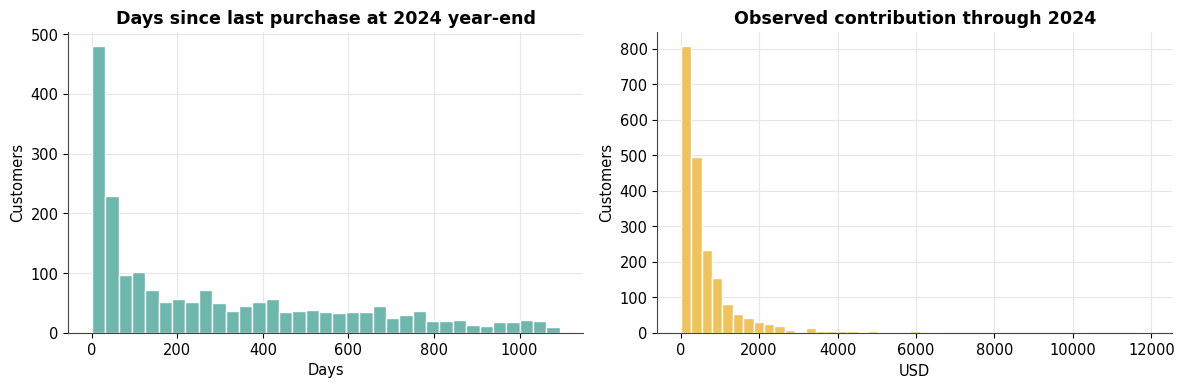

In [6]:
display(X_hold[['days_since_last_purchase', 'purchases', 'mean_contribution', 'contribution']]
        .describe().T.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_hold.days_since_last_purchase, bins=35, color=TEAL, edgecolor='white')
axes[0].set(title='Days since last purchase at 2024 year-end', xlabel='Days', ylabel='Customers')
axes[1].hist(X_hold.contribution, bins=45, color=GOLD, edgecolor='white')
axes[1].set(title='Observed contribution through 2024', xlabel='USD', ylabel='Customers')
plt.tight_layout(); plt.show()


def baseline_forecasts(X):
    return {'runrate_lifetime': (X.purchases_per_year.to_numpy(), X.contribution_per_year.to_numpy()),
            'runrate_recent': (X.count_365d.to_numpy(), X.contribution_365d.to_numpy())}


preds = X_hold[['customer_id', 'segment', 'acquisition_channel', 'contribution']].rename(
    columns={'contribution': 'calibration_contribution'}).merge(y_hold, on='customer_id')
for key, (count, contrib) in baseline_forecasts(X_hold).items():
    preds[f'count_{key}'], preds[f'contrib_{key}'] = count, contrib

## 5. Probabilistic models: BG/NBD, Pareto/NBD, and Gamma-Gamma

These "buy till you die" models treat each customer as having a private purchase rate while active and a private, unobserved moment when they stop buying for good. Both purchase models use the same three numbers per customer: repeat **frequency**, **recency** (time of last repeat purchase), and **T** (customer age).

- **BG/NBD** (Fader, Hardie, and Lee 2005): after each purchase the customer flips a weighted coin and may drop out. A customer who never repeats has never had a chance to drop out, so BG/NBD treats one-time buyers as alive with certainty.
- **Pareto/NBD** (Schmittlein, Morrison, and Colombo 1987): dropout can happen at any moment, purchase or not. This matches the simulator, where dropout happens at month-end regardless of purchasing.
- **Gamma-Gamma** (Fader, Hardie, and Lee 2005b): each customer's average contribution per purchase occasion, shrunk toward the population mean. Customers with more repeat purchases get less shrinkage. Customers with no repeat purchases receive the model's population mean.

Multiple same-day transactions are aggregated into one **purchase occasion**, since these models describe a customer's purchase *timing*. Durations are in days. Contribution forecast = expected 2025 occasions × expected contribution per occasion, which assumes purchase timing and spend are independent; we check that assumption below.

**Numerical note.** `lifetimes` computes BG/NBD expectations through `log(hyp2f1(...))`, which returns NaN when the hypergeometric term is negative (possible when the fitted `a + b < 1`). `bgnbd_expected_purchases` below evaluates the same equation directly. For Pareto/NBD, `lifetimes` can return NaN for a customer whose last purchase falls on the final calibration day; mathematically that customer's probability of being alive is exactly 1, and `paretonbd_expected_purchases` uses that limit.

In [7]:
def rfm_summary(cal_tx, cal_end):
    # Customer-day purchase occasions -> lifetimes frequency/recency/T/monetary summary.
    days = (cal_tx.assign(transaction_date=cal_tx.transaction_date.dt.normalize())
            .groupby(['customer_id', 'transaction_date'], as_index=False).contribution.sum())
    s = summary_data_from_transaction_data(days, 'customer_id', 'transaction_date', 'contribution',
                                           observation_period_end=cal_end, freq='D')
    assert (s.recency <= s['T']).all() and (s.loc[s.frequency == 0, 'recency'] == 0).all()
    return s


def bgnbd_expected_purchases(params, t, x, t_x, T):
    # Fader, Hardie & Lee (2005), eq. (10), evaluated without taking log(hyp2f1).
    r, alpha, a, b = (params[k] for k in ('r', 'alpha', 'a', 'b'))
    x, t_x, T = (np.asarray(v, dtype=float) for v in (x, t_x, T))
    hyp = hyp2f1(r + x, b + x, a + b + x - 1, t / (alpha + T + t))
    numerator = (a + b + x - 1) / (a - 1) * (1 - hyp * ((alpha + T) / (alpha + t + T)) ** (r + x))
    denominator = 1 + (x > 0) * (a / (b + np.maximum(x, 1) - 1)) * ((alpha + T) / (alpha + t_x)) ** (r + x)
    return numerator / denominator


def paretonbd_expected_purchases(model, t, x, t_x, T):
    # P(alive) x E[purchases in (T, T+t] | alive]  (Fader & Hardie 2005 note, eq. 41).
    r, alpha, s, beta = (model.params_[k] for k in ('r', 'alpha', 's', 'beta'))
    x, t_x, T = (np.asarray(v, dtype=float) for v in (x, t_x, T))
    with np.errstate(all='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        p_alive = np.asarray(model.conditional_probability_alive(x, t_x, T), dtype=float)
    p_alive = np.where(~np.isfinite(p_alive) & (t_x == T), 1.0, p_alive)  # exact limit
    if not np.isfinite(p_alive).all():
        raise ValueError('Non-finite Pareto/NBD P(alive) remained after the t_x == T limit.')
    if np.isclose(s, 1.0):
        raise ValueError('s = 1 requires the logarithmic limit of eq. 41.')
    mean_if_alive = ((r + x) * (beta + T) / ((alpha + T) * (s - 1))
                     * (1 - ((beta + T) / (beta + T + t)) ** (s - 1)))
    return p_alive * mean_if_alive, p_alive


FIT_STARTS = [None, 0.0, 1.0, -1.0]   # fixed, pre-declared starting points (log scale) for restarts


def robust_fit(fitter_cls, penalizer, *data):
    # lifetimes raises ConvergenceError whenever SciPy's BFGS reports success=False, including the
    # common "precision loss" case where the gradient is already ~0. Its message suggests adding a
    # penalizer; we instead restart the same unpenalized likelihood from fixed starting points.
    n_params = 3 if fitter_cls is GammaGammaFitter else 4
    for attempt, start in enumerate(FIT_STARTS):
        x0 = None if start is None else np.full(n_params, start)
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                return fitter_cls(penalizer_coef=penalizer).fit(*data, initial_params=x0), attempt
        except ConvergenceError:
            continue
    raise ConvergenceError(f'{fitter_cls.__name__} failed from every pre-declared starting point.')


def fit_probabilistic(cal_tx, cal_end, horizon_days):
    # Fit BG/NBD, Pareto/NBD and Gamma-Gamma on calibration data; return per-customer forecasts.
    s = rfm_summary(cal_tx, cal_end)
    x, tx, T = s.frequency.values, s.recency.values, s['T'].values
    info = {'fit_warnings': {}, 'fit_restarts': {}}
    eligible = (s.frequency > 0) & (s.monetary_value > 0)
    fitted = {}
    for name, cls, pen, data in [('bgnbd', BetaGeoFitter, BGNBD_PENALIZER, (s.frequency, s.recency, s['T'])),
                                 ('pareto', ParetoNBDFitter, PARETO_PENALIZER, (s.frequency, s.recency, s['T'])),
                                 ('gamma_gamma', GammaGammaFitter, GG_PENALIZER,
                                  (s.frequency[eligible], s.monetary_value[eligible]))]:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            fitted[name], info['fit_restarts'][name] = robust_fit(cls, pen, *data)
        info['fit_warnings'][name] = sum(issubclass(w.category, RuntimeWarning) for w in caught)
        # Warnings can come from trial parameter values during the search; the final fit must be clean.
        assert np.isfinite(fitted[name]._negative_log_likelihood_), f'{name}: non-finite final likelihood'
    bg, pn, gg = fitted['bgnbd'], fitted['pareto'], fitted['gamma_gamma']
    out = pd.DataFrame(index=s.index)
    out['bg_occasions'] = bgnbd_expected_purchases(bg.params_, horizon_days, x, tx, T)
    out['bg_p_alive'] = np.asarray(bg.conditional_probability_alive(x, tx, T), dtype=float)
    out['pareto_occasions'], out['pareto_p_alive'] = paretonbd_expected_purchases(pn, horizon_days, x, tx, T)
    p, q, v = (gg.params_[k] for k in ('p', 'q', 'v'))
    info['gg_q'] = q
    if q > 1:   # population mean is finite: use Gamma-Gamma for every customer
        out['gg_value'] = np.asarray(gg.conditional_expected_average_profit(s.frequency, s.monetary_value), float)
    else:       # population mean undefined; zero-repeat customers get the observed repeat-occasion mean
        out['gg_value'] = np.where(eligible, gg.conditional_expected_average_profit(s.frequency, s.monetary_value),
                                   s.monetary_value[eligible].mean())
    out['contrib_bgnbd_gg'] = out.bg_occasions * out.gg_value
    out['contrib_pareto_gg'] = out.pareto_occasions * out.gg_value
    if not np.isfinite(out.to_numpy(dtype=float)).all() or (out.to_numpy(dtype=float) < 0).any():
        raise ValueError('Invalid probabilistic forecast; do not replace with zero.')
    info['spearman_freq_value'] = spearmanr(s.frequency[eligible], s.monetary_value[eligible])[0]
    return out, {'bg': bg, 'pareto': pn, 'gg': gg, 'summary': s, 'eligible': eligible, **info}


t0 = time.time()
prob, fits = fit_probabilistic(calibration, CAL_END, HORIZON_DAYS)
summ = fits['summary']
print(f'Fitted in {time.time() - t0:.1f}s | RuntimeWarnings during the search: {fits["fit_warnings"]}'
      f' | restarts needed: {fits["fit_restarts"]}')
print('BG/NBD     ', {k: round(v, 4) for k, v in fits['bg'].params_.items()})
print('Pareto/NBD ', {k: round(v, 4) for k, v in fits['pareto'].params_.items()})
print('Gamma-Gamma', {k: round(v, 4) for k, v in fits['gg'].params_.items()})
print(f"Gamma-Gamma eligible (1+ repeat occasion): {fits['eligible'].sum()} of {len(summ)}")
print(f"Spearman(frequency, mean repeat contribution) = {fits['spearman_freq_value']:.3f}")

r, a, s_, beta = fits['bg'].params_['r'], fits['bg'].params_['a'], fits['pareto'].params_['s'], fits['pareto'].params_['beta']
print(f"\nPareto/NBD mean dropout rate: {s_ / beta:.5f} per day = {1 - np.exp(-30.4375 * s_ / beta):.1%} per month")
print(f"BG/NBD mean dropout probability per purchase: {a / (a + fits['bg'].params_['b']):.1%}")
print(f"Gamma-Gamma population mean contribution per occasion: "
      f"${fits['gg'].params_['p'] * fits['gg'].params_['v'] / (fits['gg'].params_['q'] - 1):.2f}")

preds = preds.merge(prob.reset_index(), on='customer_id', how='left', validate='one_to_one')
preds['count_bgnbd_gg'], preds['count_pareto_gg'] = preds.bg_occasions, preds.pareto_occasions

Fitted in 7.6s | RuntimeWarnings during the search: {'bgnbd': 0, 'pareto': 0, 'gamma_gamma': 0} | restarts needed: {'bgnbd': 0, 'pareto': 0, 'gamma_gamma': 0}
BG/NBD      {'r': 1.0925, 'alpha': 39.6938, 'a': 0.6284, 'b': 9.3217}
Pareto/NBD  {'r': 1.5908, 'alpha': 60.3775, 's': 7.451, 'beta': 5914.8518}
Gamma-Gamma {'p': 4.945, 'q': 4.589, 'v': 38.7431}
Gamma-Gamma eligible (1+ repeat occasion): 1817 of 2000
Spearman(frequency, mean repeat contribution) = -0.085

Pareto/NBD mean dropout rate: 0.00126 per day = 3.8% per month
BG/NBD mean dropout probability per purchase: 6.3%
Gamma-Gamma population mean contribution per occasion: $53.38


**Reading these parameters.** Pareto/NBD's fitted average dropout rate translates into a monthly probability that can be compared with the simulator's own month-end dropout probabilities (about 2% to 4.3% by segment, rising slightly with tenure). This is an evaluation-only sanity check, not something a real business could observe. The Spearman correlation between repeat frequency and average spend is small, which supports, but does not prove, Gamma-Gamma's independence assumption.

### 5.1 Regularization sensitivity (calibration data only)

How much does the penalizer matter? This table refits each model at several penalties and reports the fitted parameters and the **total forecast** for 2025. No 2025 outcomes are used here, so nothing in this table can be tuned to the holdout. It reports how many customers `lifetimes`' own function leaves as NaN versus the direct evaluation used in this notebook.

In [8]:
x, tx, T = summ.frequency.values, summ.recency.values, summ['T'].values
rows = []
for pen in [0.0, 0.001, 0.01, 0.1, 0.25, 0.5, 1.0]:
    with warnings.catch_warnings(), np.errstate(all='ignore'):
        warnings.simplefilter('ignore')
        m, _ = robust_fit(BetaGeoFitter, pen, summ.frequency, summ.recency, summ['T'])
        lib = np.asarray(m.conditional_expected_number_of_purchases_up_to_time(HORIZON_DAYS, x, tx, T), float)
    direct = bgnbd_expected_purchases(m.params_, HORIZON_DAYS, x, tx, T)
    ok = np.isfinite(lib)
    rows.append({'penalizer': pen, **{k: m.params_[k] for k in ('r', 'alpha', 'a', 'b')},
                 'lifetimes_NaN_customers': int((~ok).sum()), 'direct_NaN_customers': int((~np.isfinite(direct)).sum()),
                 'max_abs_difference_where_both_finite': float(np.abs(lib[ok] - direct[ok]).max()),
                 'forecast_2025_occasions': direct.sum()})
bg_sens = pd.DataFrame(rows)
display(bg_sens.round(4))

rows = []
eligible = fits['eligible']
for pen in [0.0, 0.01, 0.05, 0.1, 0.2]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        g, _ = robust_fit(GammaGammaFitter, pen, summ.frequency[eligible], summ.monetary_value[eligible])
    est = g.conditional_expected_average_profit(summ.frequency[eligible], summ.monetary_value[eligible])
    rows.append({'penalizer': pen, **{k: g.params_[k] for k in ('p', 'q', 'v')}, 'q_above_1': g.params_['q'] > 1,
                 'mean_prediction': est.mean(), 'max_prediction': est.max()})
gg_sens = pd.DataFrame(rows)
display(gg_sens.round(3))
bg_sens.to_csv(OUTPUT / 'bgnbd_regularization_sensitivity.csv', index=False)
gg_sens.to_csv(OUTPUT / 'gamma_gamma_regularization_sensitivity.csv', index=False)
assert (bg_sens.direct_NaN_customers == 0).all()

,penalizer,r,alpha,a,b,lifetimes_NaN_customers,direct_NaN_customers,max_abs_difference_where_both_finite,forecast_2025_occasions
0,0.000,1.0925,39.6938,0.6284,9.3217,0,0,0.0,8922.0969
1,0.001,1.1023,39.9536,0.3435,3.4630,0,0,0.0,9424.8532
2,0.010,1.0546,38.1769,0.2221,1.5804,0,0,0.0,9816.5598
3,0.100,0.7932,28.5878,0.1343,0.6559,183,0,0.0,10260.1411
4,0.250,0.6341,22.7714,0.1063,0.4528,50,0,0.0,10452.2442
5,0.500,0.5160,18.4648,0.0872,0.3391,18,0,0.0,10603.7525
6,1.000,0.4092,14.5869,0.0700,0.2518,0,0,0.0,10760.4323


,penalizer,p,q,v,q_above_1,mean_prediction,max_prediction
0,0.00,4.945,4.589,38.743,True,52.457,210.167
1,0.01,4.263,0.795,4.168,False,54.591,344.723
2,0.05,1.767,0.371,1.711,False,59.868,505.778
3,0.10,1.177,0.288,1.125,False,68.418,823.384
4,0.20,0.786,0.232,0.736,False,324.204,14206.127


Two lessons for the article. First, a library returning NaN is not the same as a model being invalid; check the math before changing the model. Second, the penalty is not a harmless "stability" knob for these small parametric models. Stronger penalties steadily raise BG/NBD's total forecast and drive Gamma-Gamma's `q` below 1. The default of no penalty was fixed in Section 1 because it is the library default, not because of 2025 accuracy.

## 6. Supervised machine learning with a time-aware origin

**No 2025 labels are used for fitting, feature engineering, or preprocessing.** We train on customers acquired by **2023-12-31**, with features as of that date and outcomes during **calendar 2024**. The fitted models are then applied to features as of 2024-12-31 to forecast 2025. This is a single rolling-origin window, not cross-validation. Separate models predict transactions and contribution.

The ML models see segment and acquisition channel, which the probabilistic models do not. They also learn, from one year of history, how much this particular customer base tends to decay. Both are legitimate advantages a real business could use, and they partly explain any accuracy gap.

In [9]:
FEATURES = [c for c in X_hold.columns if c not in ('customer_id', 'acquisition_date')]
CATEGORICAL = ['segment', 'acquisition_channel']
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
ML_FACTORIES = {
    'random_forest': lambda: RandomForestRegressor(n_estimators=180, min_samples_leaf=8, max_features=0.85,
                                                   random_state=SEED, n_jobs=-1),
    'grad_boost': lambda: HistGradientBoostingRegressor(max_iter=160, max_leaf_nodes=12, learning_rate=0.055,
                                                        l2_regularization=5, random_state=SEED)}


def fit_ml(profiles, cal_tx, all_tx, X_forecast, train_end=ML_TRAIN_END, cal_end=CAL_END):
    X_train = features_at(train_end, profiles, cal_tx)
    y_train = outcomes_between(train_end, cal_end, X_train.customer_id, all_tx)
    assert X_train.acquisition_date.max() <= train_end and y_train.actual_purchases.sum() > 0
    out = {}
    for key, factory in ML_FACTORIES.items():
        for target, prefix in [('actual_purchases', 'count'), ('actual_contribution', 'contrib')]:
            pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
                                     ('num', 'passthrough', NUMERIC)])
            model = Pipeline([('prepare', pre), ('predict', factory())]).fit(X_train[FEATURES], y_train[target])
            out[f'{prefix}_{key}'] = np.maximum(0, model.predict(X_forecast[FEATURES]))
    return out, len(X_train)


ml_preds, n_train = fit_ml(profiles, calibration, all_transactions, X_hold)
for col, values in ml_preds.items():
    preds[col] = values
print('ML training customers:', n_train, '| forecast customers:', len(X_hold),
      '| 2025 labels used for training: none')

ML training customers: 1623 | forecast customers: 2000 | 2025 labels used for training: none


## 7. Holdout comparison

**MAE** and **RMSE** measure customer-level error. **Signed portfolio error** shows over- or underforecasting of the total. A model can get the total right while missing individual customers, and vice versa.

Purchase counts are not directly comparable across families: the probabilistic models forecast **purchase occasions** (distinct purchase days), while the baselines and ML models forecast **raw transactions**. Contribution forecasts are directly comparable for all six models.

In [10]:
def score(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    return {'MAE': mean_absolute_error(a, p), 'RMSE': np.sqrt(mean_squared_error(a, p)),
            'Actual total': a.sum(), 'Forecast total': p.sum(),
            'Signed portfolio error %': 100 * (p.sum() - a.sum()) / a.sum()}


def score_all(preds):
    rows = []
    for key in MODELS:
        rows.append({'model': key, 'Model': LABEL[key], 'Target': '2025 contribution ($)',
                     **score(preds.actual_contribution, preds[f'contrib_{key}'])})
        unit = 'occasions' if key in ('bgnbd_gg', 'pareto_gg') else 'purchases'
        rows.append({'model': key, 'Model': LABEL[key], 'Target': f'2025 {unit}',
                     **score(preds[f'actual_{unit}'], preds[f'count_{key}'])})
    return pd.DataFrame(rows)


results = score_all(preds)
contrib_results = results[results.Target == '2025 contribution ($)'].sort_values('MAE')
print('2025 contribution forecasts (all six models are directly comparable):')
display(contrib_results.drop(columns='model').round(2))
print('2025 purchase-count forecasts (occasions and transactions are different units):')
display(results[results.Target != '2025 contribution ($)'].drop(columns='model').round(2))
results.to_csv(OUTPUT / 'model_metrics_2025.csv', index=False)

2025 contribution forecasts (all six models are directly comparable):


,Model,Target,MAE,RMSE,Actual total,Forecast total,Signed portfolio error %
6,Pareto/NBD + Gamma-Gamma,2025 contribution ($),113.83,231.38,408446.84,412655.05,1.03
4,BG/NBD + Gamma-Gamma,2025 contribution ($),119.14,230.83,408446.84,456341.66,11.73
8,Random forest,2025 contribution ($),125.41,314.68,408446.84,424079.77,3.83
10,Gradient boosting,2025 contribution ($),127.71,314.56,408446.84,422674.58,3.48
2,Run-rate (last 365 days),2025 contribution ($),153.76,299.30,408446.84,574733.64,40.71
0,Run-rate (lifetime),2025 contribution ($),227.11,377.63,408446.84,777740.66,90.41


2025 purchase-count forecasts (occasions and transactions are different units):


,Model,Target,MAE,RMSE,Actual total,Forecast total,Signed portfolio error %
1,Run-rate (lifetime),2025 purchases,4.49,6.79,8141.0,15496.72,90.35
3,Run-rate (last 365 days),2025 purchases,3.08,5.58,8141.0,11510.00,41.38
5,BG/NBD + Gamma-Gamma,2025 occasions,2.33,4.21,7952.0,8922.10,12.20
7,Pareto/NBD + Gamma-Gamma,2025 occasions,2.22,4.16,7952.0,8059.31,1.35
9,Random forest,2025 purchases,2.35,4.47,8141.0,8418.04,3.40
11,Gradient boosting,2025 purchases,2.41,4.59,8141.0,8606.85,5.72


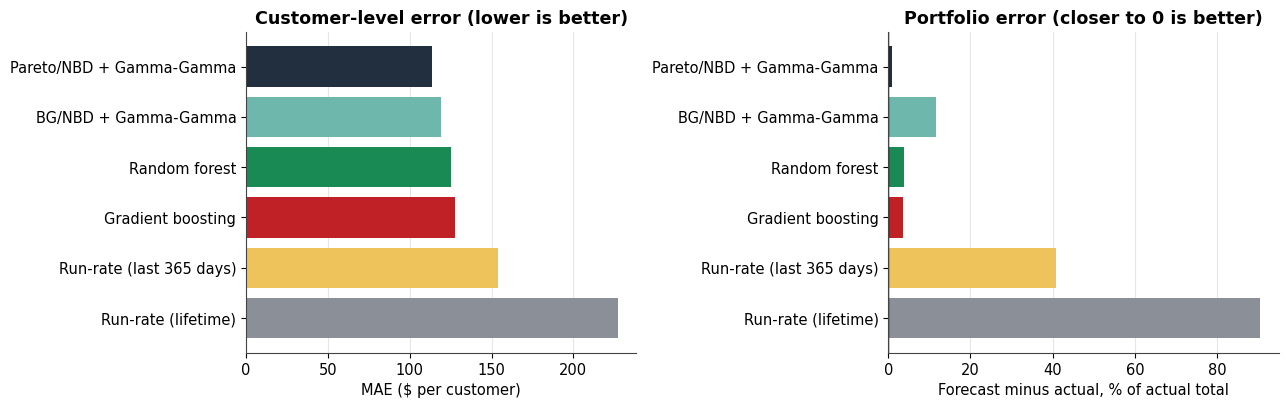

In [11]:
order = contrib_results.model.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].barh([LABEL[k] for k in order], contrib_results.MAE, color=[COLOR[k] for k in order])
axes[0].invert_yaxis(); axes[0].set(xlabel='MAE ($ per customer)', title='Customer-level error (lower is better)')
axes[1].barh([LABEL[k] for k in order], contrib_results['Signed portfolio error %'], color=[COLOR[k] for k in order])
axes[1].axvline(0, color='black', lw=1); axes[1].invert_yaxis()
axes[1].set(xlabel='Forecast minus actual, % of actual total', title='Portfolio error (closer to 0 is better)')
for ax in axes: ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(OUTPUT / 'fig_holdout_comparison.png', dpi=200); plt.show()

## 8. Where the probabilistic forecasts go wrong

A contribution forecast can miss because it expects too many purchase occasions, too much contribution per occasion, or both. This table splits the two. It is descriptive: multiplying two aggregate averages does not reproduce every customer's forecast exactly.

The BG/NBD versus Pareto/NBD contrast isolates **one assumption**: when dropout can happen. Both share the same Gamma-Gamma spend model. BG/NBD gives every one-time buyer a 100% chance of still being active, because in that model a customer can only drop out right after a purchase.

In [12]:
rows = []
for key, occ in [('bgnbd_gg', 'bg_occasions'), ('pareto_gg', 'pareto_occasions')]:
    po, ao = preds[occ].sum(), preds.actual_occasions.sum()
    pc, ac = preds[f'contrib_{key}'].sum(), preds.actual_contribution.sum()
    rows.append({'Model': LABEL[key], 'Forecast occasions': po, 'Actual occasions': ao,
                 'Occasion error %': 100 * (po / ao - 1),
                 'Forecast $/occasion': pc / po, 'Actual $/occasion': ac / ao,
                 '$/occasion error %': 100 * ((pc / po) / (ac / ao) - 1),
                 'Contribution error %': 100 * (pc / ac - 1)})
decomp = pd.DataFrame(rows)
display(decomp.round(2))
decomp.to_csv(OUTPUT / 'probabilistic_error_decomposition.csv', index=False)

one_time = summ.frequency.values == 0
print(f'Customers with no repeat purchase by 2024 year-end: {one_time.sum()}')
print(f"  Mean P(alive) under BG/NBD:     {prob.bg_p_alive.values[one_time].mean():.3f}")
print(f"  Mean P(alive) under Pareto/NBD: {prob.pareto_p_alive.values[one_time].mean():.3f}")
oc = preds.set_index('customer_id').loc[summ.index]
print(f"  2025 occasions forecast  BG/NBD: {oc.bg_occasions.values[one_time].sum():.0f}"
      f" | Pareto/NBD: {oc.pareto_occasions.values[one_time].sum():.0f}"
      f" | actual: {oc.actual_occasions.values[one_time].sum():.0f}")

,Model,Forecast occasions,Actual occasions,Occasion error %,Forecast $/occasion,Actual $/occasion,$/occasion error %,Contribution error %
0,BG/NBD + Gamma-Gamma,8922.10,7952.0,12.20,51.15,51.36,-0.42,11.73
1,Pareto/NBD + Gamma-Gamma,8059.31,7952.0,1.35,51.20,51.36,-0.31,1.03


Customers with no repeat purchase by 2024 year-end: 183
  Mean P(alive) under BG/NBD:     1.000
  Mean P(alive) under Pareto/NBD: 0.168
  2025 occasions forecast  BG/NBD: 128 | Pareto/NBD: 38 | actual: 32


## 9. Residuals and bootstrap uncertainty

The scatter plots compare forecasts with outcomes customer by customer (the diagonal is a perfect forecast, not a fitted line). The bootstrap resamples **customers** with replacement, keeping each customer's forecast and outcome together, to show how much the metrics move with the sample. These intervals describe sampling variation within one simulated world; the replication study in Section 13 addresses variation across worlds.

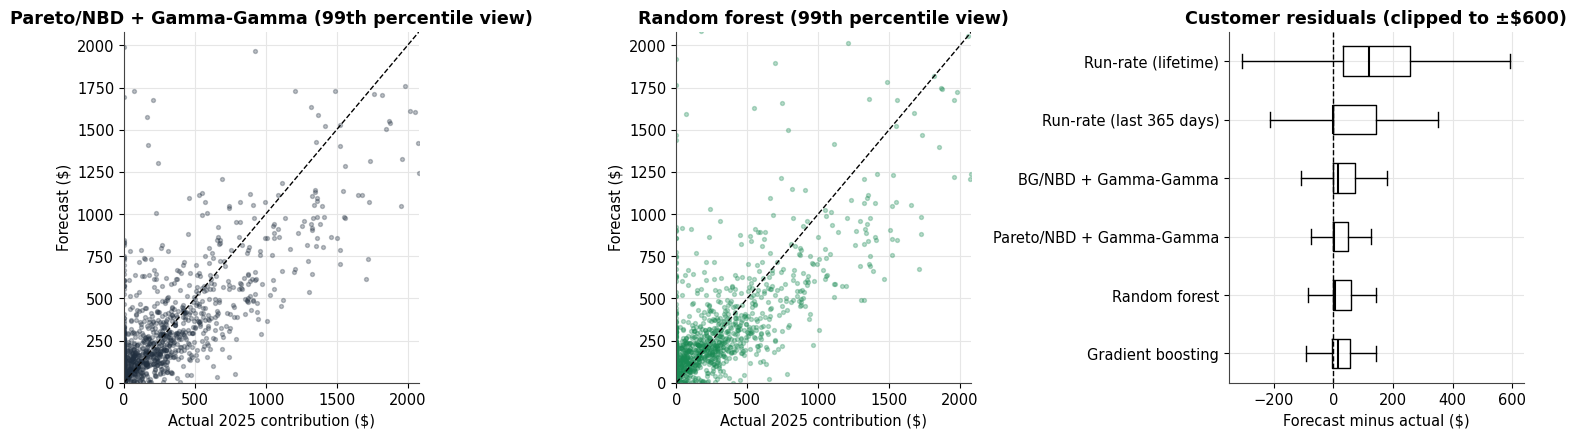

Charts limit the visible range only; every metric uses all customers.


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
cap = np.percentile(preds.actual_contribution, 99)
for ax, key in zip(axes[:2], ['pareto_gg', 'random_forest']):
    ax.scatter(preds.actual_contribution, preds[f'contrib_{key}'], s=8, alpha=0.3, color=COLOR[key])
    ax.plot([0, cap], [0, cap], ls='--', color='black', lw=1)
    ax.set(xlim=(0, cap), ylim=(0, cap), xlabel='Actual 2025 contribution ($)',
           ylabel='Forecast ($)', title=f'{LABEL[key]} (99th percentile view)')
resid = [(preds[f'contrib_{k}'] - preds.actual_contribution).clip(-600, 600) for k in MODELS]
try:   # Matplotlib >= 3.10
    axes[2].boxplot(resid, showfliers=False, orientation='horizontal', tick_labels=[LABEL[k] for k in MODELS],
                    medianprops={'color': 'black', 'lw': 1.5})
except TypeError:
    axes[2].boxplot(resid, showfliers=False, vert=False, labels=[LABEL[k] for k in MODELS],
                    medianprops={'color': 'black', 'lw': 1.5})
axes[2].invert_yaxis()
axes[2].axvline(0, color='black', ls='--', lw=1)
axes[2].set(xlabel='Forecast minus actual ($)', title='Customer residuals (clipped to ±$600)')
plt.tight_layout(); plt.savefig(OUTPUT / 'fig_residuals.png', dpi=200); plt.show()
print('Charts limit the visible range only; every metric uses all customers.')

In [14]:
rng = np.random.default_rng(SEED + 2)
actual = preds.actual_contribution.to_numpy(float)
F = np.column_stack([preds[f'contrib_{k}'].to_numpy(float) for k in MODELS])
boot_mae = np.empty((BOOTSTRAP_DRAWS, len(MODELS)))
boot_port = np.empty_like(boot_mae)
for b in range(BOOTSTRAP_DRAWS):
    idx = rng.integers(0, len(actual), size=len(actual))
    err = F[idx] - actual[idx, None]
    boot_mae[b] = np.abs(err).mean(axis=0)
    boot_port[b] = 100 * err.sum(axis=0) / actual[idx].sum()
ci = pd.DataFrame({'Model': [LABEL[k] for k in MODELS],
                   'MAE': np.abs(F - actual[:, None]).mean(axis=0),
                   'MAE 2.5%': np.quantile(boot_mae, .025, axis=0), 'MAE 97.5%': np.quantile(boot_mae, .975, axis=0),
                   'Portfolio error %': 100 * (F.sum(axis=0) / actual.sum() - 1),
                   'Portfolio 2.5%': np.quantile(boot_port, .025, axis=0),
                   'Portfolio 97.5%': np.quantile(boot_port, .975, axis=0)}).sort_values('MAE')
display(ci.round(2))
ci.to_csv(OUTPUT / 'bootstrap_metric_intervals_2025.csv', index=False)
keys = list(MODELS)
for a_, b_ in [('pareto_gg', 'random_forest'), ('pareto_gg', 'bgnbd_gg'), ('random_forest', 'grad_boost')]:
    d = boot_mae[:, keys.index(a_)] - boot_mae[:, keys.index(b_)]
    lo, mid, hi = np.quantile(d, [.025, .5, .975])
    print(f'Paired bootstrap MAE difference, {LABEL[a_]} minus {LABEL[b_]}: '
          f'median {mid:+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}] $/customer')

,Model,MAE,MAE 2.5%,MAE 97.5%,Portfolio error %,Portfolio 2.5%,Portfolio 97.5%
3,Pareto/NBD + Gamma-Gamma,113.83,105.65,121.28,1.03,-3.82,6.28
2,BG/NBD + Gamma-Gamma,119.14,110.82,127.26,11.73,6.29,17.52
4,Random forest,125.41,114.37,138.01,3.83,-2.88,11.10
5,Gradient boosting,127.71,116.53,140.51,3.48,-3.13,10.60
1,Run-rate (last 365 days),153.76,143.02,164.87,40.71,32.82,48.69
0,Run-rate (lifetime),227.11,213.51,240.09,90.41,79.02,102.64


Paired bootstrap MAE difference, Pareto/NBD + Gamma-Gamma minus Random forest: median -11.19, 95% interval [-19.73, -5.17] $/customer
Paired bootstrap MAE difference, Pareto/NBD + Gamma-Gamma minus BG/NBD + Gamma-Gamma: median -5.36, 95% interval [-7.05, -3.59] $/customer
Paired bootstrap MAE difference, Random forest minus Gradient boosting: median -2.31, 95% interval [-4.86, +0.01] $/customer


## 10. Segment diagnostics and high-value customers

Error by profile segment and by **historical** contribution tertile (defined from calibration data, never from 2025 outcomes), plus the top 10% of customers ranked by calibration contribution.

In [15]:
preds['historical_band'] = pd.qcut(preds.calibration_contribution.rank(method='first'), 3,
                                   labels=['Low', 'Middle', 'High'])
rows = []
for dim in ['segment', 'historical_band']:
    for name, g in preds.groupby(dim, observed=True):
        for key in MODELS:
            rows.append({'Dimension': dim, 'Group': str(name), 'Customers': len(g), 'Model': LABEL[key],
                         **score(g.actual_contribution, g[f'contrib_{key}'])})
seg = pd.DataFrame(rows)
display(seg.pivot_table(index=['Dimension', 'Group'], columns='Model', values='MAE', sort=False).round(1))
display(seg.pivot_table(index=['Dimension', 'Group'], columns='Model', values='Signed portfolio error %',
                        sort=False).round(1))
seg.to_csv(OUTPUT / 'segment_metrics_2025.csv', index=False)

top = preds.loc[preds.calibration_contribution >= preds.calibration_contribution.quantile(.90)]
print(f'Top historical decile: {len(top)} customers, ${top.actual_contribution.sum():,.0f} actual 2025 contribution '
      f'({top.actual_contribution.sum() / preds.actual_contribution.sum():.0%} of the total)')
display(pd.DataFrame([{'Model': LABEL[k], **score(top.actual_contribution, top[f'contrib_{k}'])}
                      for k in MODELS]).round(2))

Model                       Run-rate (lifetime)  Run-rate (last 365 days)  \
Dimension       Group                                                       
segment         Enthusiast                469.6                     357.8   
                Occasional                157.8                      95.7   
                Regular                   228.7                     154.8   
historical_band Low                        73.5                      39.3   
                Middle                    179.0                     114.2   
                High                      428.7                     307.7   

Model                       BG/NBD + Gamma-Gamma  Pareto/NBD + Gamma-Gamma  \
Dimension       Group                                                        
segment         Enthusiast                 270.3                     279.7   
                Occasional                  80.0                      69.3   
                Regular                    114.7                     111.1   
historical_band Low                         41.0                      31.9   
                Middle                      88.1                      82.9   
                High                       228.3                     226.7   

Model                       Random forest  Gradient boosting  
Dimension       Group                                         
segment         Enthusiast          332.6              324.1  
                Occasional           68.4               72.3  
                Regular             123.8              128.0  
historical_band Low                  36.1               39.5  
                Middle               85.8               89.9  
                High                254.2              253.6

Model                       Run-rate (lifetime)  Run-rate (last 365 days)  \
Dimension       Group                                                       
segment         Enthusiast                 57.5                      26.2   
                Occasional                174.5                      77.6   
                Regular                    87.4                      39.5   
historical_band Low                       200.6                      46.2   
                Middle                    120.9                      43.6   
                High                       75.8                      39.6   

Model                       BG/NBD + Gamma-Gamma  Pareto/NBD + Gamma-Gamma  \
Dimension       Group                                                        
segment         Enthusiast                  -2.3                      -9.2   
                Occasional                  47.1                      24.2   
                Regular                     10.7                       1.5   
historical_band Low                         57.8                      17.1   
                Middle                      13.7                       3.3   
                High                         8.4                      -0.5   

Model                       Random forest  Gradient boosting  
Dimension       Group                                         
segment         Enthusiast           -0.5                4.4  
                Occasional           15.0               11.8  
                Regular               3.3               -1.5  
historical_band Low                  37.3               42.2  
                Middle                1.1               -0.7  
                High                  2.5                2.2

Top historical decile: 200 customers, $182,707 actual 2025 contribution (45% of the total)


,Model,MAE,RMSE,Actual total,Forecast total,Signed portfolio error %
0,Run-rate (lifetime),630.68,888.98,182707.14,279706.60,53.09
1,Run-rate (last 365 days),494.21,731.71,182707.14,236941.97,29.68
2,BG/NBD + Gamma-Gamma,394.98,572.96,182707.14,186361.44,2.00
3,Pareto/NBD + Gamma-Gamma,404.39,580.53,182707.14,170369.36,-6.75
4,Random forest,468.63,871.30,182707.14,175707.02,-3.83
5,Gradient boosting,460.64,863.41,182707.14,178738.75,-2.17


## 11. Evaluation-only audit: did the models know who was still active?

Because this is a simulation, we know which customers were truly still active on 2024-12-31. A real business never does. Here we compare each probabilistic model's **P(alive)** with that hidden truth. This uses the ground-truth file only for scoring; nothing here feeds back into the models.

,Model,Mean P(alive),True share alive,Expected alive customers,Actually alive,AUC,Brier score
0,BG/NBD,0.599,0.466,1197.106,932,0.800,0.166
1,Pareto/NBD,0.487,0.466,974.908,932,0.953,0.080


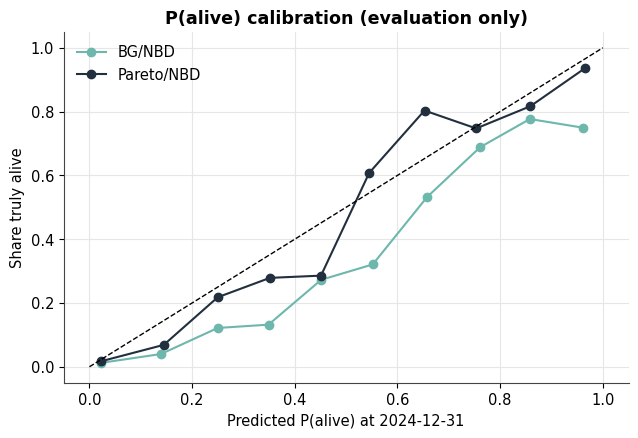

In [16]:
truth_path = INPUT / 'simulation_ground_truth.csv'
if truth_path.exists():
    truth = pd.read_csv(truth_path, parse_dates=['latent_dropout_date'])
    alive_2024 = truth.latent_dropout_date.isna() | (truth.latent_dropout_date > CAL_END)
    audit = (prob[['bg_p_alive', 'pareto_p_alive']].reset_index()
             .merge(truth.assign(alive=alive_2024)[['customer_id', 'alive', 'active_at_holdout_end']],
                    on='customer_id'))
    rows = []
    for col, name in [('bg_p_alive', 'BG/NBD'), ('pareto_p_alive', 'Pareto/NBD')]:
        rows.append({'Model': name, 'Mean P(alive)': audit[col].mean(), 'True share alive': audit.alive.mean(),
                     'Expected alive customers': audit[col].sum(), 'Actually alive': int(audit.alive.sum()),
                     'AUC': roc_auc_score(audit.alive, audit[col]),
                     'Brier score': np.mean((audit[col] - audit.alive) ** 2)})
    palive = pd.DataFrame(rows)
    display(palive.round(3))
    palive.to_csv(OUTPUT / 'p_alive_audit.csv', index=False)

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    bins = np.linspace(0, 1, 11)
    for col, name, color in [('bg_p_alive', 'BG/NBD', TEAL), ('pareto_p_alive', 'Pareto/NBD', NAVY)]:
        b = pd.cut(audit[col], bins, include_lowest=True)
        cal = audit.groupby(b, observed=True).agg(pred=(col, 'mean'), obs=('alive', 'mean'), n=('alive', 'size'))
        ax.plot(cal.pred, cal.obs, marker='o', color=color, label=name)
    ax.plot([0, 1], [0, 1], ls='--', color='black', lw=1)
    ax.set(xlabel='Predicted P(alive) at 2024-12-31', ylabel='Share truly alive',
           title='P(alive) calibration (evaluation only)')
    ax.legend(); plt.tight_layout(); plt.savefig(OUTPUT / 'fig_p_alive_calibration.png', dpi=200); plt.show()
else:
    print('No simulator truth file supplied; the forecast comparison is complete without it.')

## 12. From next-year value to lifetime value

Everything above forecasts **one year**, undiscounted. Customer *lifetime* value needs a longer horizon and a discount rate, as in Part 1. The probabilistic models extend naturally: their expected purchases can be evaluated at any future time. The ML models cannot, at least not without several years of labeled outcomes to learn from.

Below, each probabilistic model projects **36 months** of contribution, discounted monthly at a **10% annual rate**. The 2025 slice of this projection is the same forecast scored in Section 7. Years 2 and 3 **cannot be validated** here because the simulation stops at 2025-12-31. Treat them as an illustration of the method, not a tested result.

,Model,Year 1,Year 2,Year 3,3-year discounted total,Share held by top 10% of customers
0,BG/NBD + Gamma-Gamma,436356.58,324896.07,255222.99,1016475.64,0.48
1,Pareto/NBD + Gamma-Gamma,395087.40,240916.91,149960.60,785964.91,0.50
2,"Run-rate (lifetime), every customer assumed ac...",741546.62,674133.30,612848.45,2028528.37,0.40


For reference, actual undiscounted 2025 contribution was $408,447.


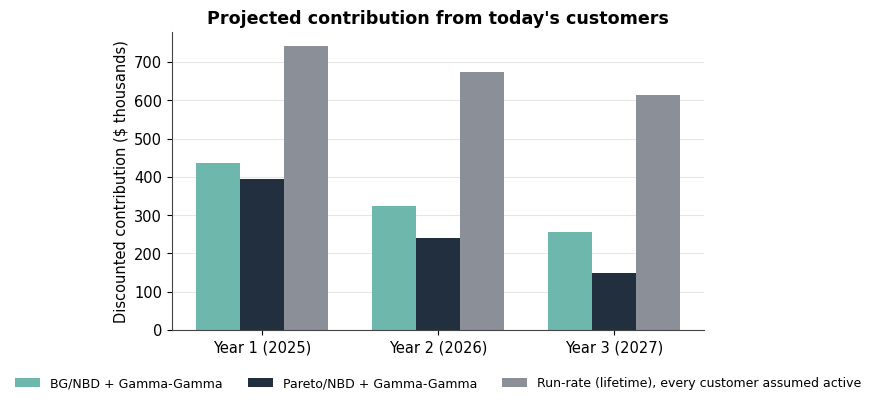

In [17]:
def discounted_projection(fits, months=PROJECTION_MONTHS, annual_rate=ANNUAL_DISCOUNT_RATE):
    s = fits['summary']
    x, tx, T = s.frequency.values, s.recency.values, s['T'].values
    value = (prob.loc[s.index, 'gg_value']).values
    step = 365.25 / 12
    out = {}
    for name, fn in [('BG/NBD + Gamma-Gamma', lambda t: bgnbd_expected_purchases(fits['bg'].params_, t, x, tx, T)),
                     ('Pareto/NBD + Gamma-Gamma', lambda t: paretonbd_expected_purchases(fits['pareto'], t, x, tx, T)[0])]:
        cumulative = np.column_stack([np.zeros(len(x))] + [fn(k * step) for k in range(1, months + 1)])
        monthly = np.diff(cumulative, axis=1)
        discount = (1 + annual_rate) ** (-(np.arange(1, months + 1) - 0.5) / 12)
        out[name] = pd.DataFrame({'customer_id': s.index,
                                  **{f'year_{y}': (monthly[:, 12 * (y - 1):12 * y] * discount[12 * (y - 1):12 * y]).sum(axis=1) * value
                                     for y in range(1, months // 12 + 1)}})
    return out


proj = discounted_projection(fits)
rows = []
for name, df in proj.items():
    total = df.drop(columns='customer_id').sum(axis=1)
    rows.append({'Model': name, **{c.replace('_', ' ').title(): df[c].sum() for c in df.columns if c != 'customer_id'},
                 '3-year discounted total': total.sum(),
                 'Share held by top 10% of customers': total.nlargest(len(total) // 10).sum() / total.sum()})
naive = X_hold.contribution_per_year.values
naive_disc = sum(naive * (1 + ANNUAL_DISCOUNT_RATE) ** (-(y - 0.5)) for y in (1, 2, 3))
rows.append({'Model': 'Run-rate (lifetime), every customer assumed active', 'Year 1': naive.sum() / 1.1 ** 0.5,
             'Year 2': naive.sum() / 1.1 ** 1.5, 'Year 3': naive.sum() / 1.1 ** 2.5, '3-year discounted total': naive_disc.sum(),
             'Share held by top 10% of customers': np.sort(naive_disc)[::-1][:len(naive) // 10].sum() / naive_disc.sum()})
clv3 = pd.DataFrame(rows)
display(clv3.round(2))
clv3.to_csv(OUTPUT / 'three_year_discounted_projection.csv', index=False)
print(f"For reference, actual undiscounted 2025 contribution was ${preds.actual_contribution.sum():,.0f}.")

fig, ax = plt.subplots(figsize=(8, 4.2))
w = 0.25
for i, (name, color) in enumerate([('BG/NBD + Gamma-Gamma', TEAL), ('Pareto/NBD + Gamma-Gamma', NAVY),
                                   ('Run-rate (lifetime), every customer assumed active', GRAY)]):
    vals = clv3.set_index('Model').loc[name, ['Year 1', 'Year 2', 'Year 3']].values / 1000
    ax.bar(np.arange(3) + (i - 1) * w, vals, width=w, color=color, label=name)
ax.set(xticks=range(3), xticklabels=['Year 1 (2025)', 'Year 2 (2026)', 'Year 3 (2027)'],
       ylabel='Discounted contribution ($ thousands)', title='Projected contribution from today\'s customers')
ax.grid(axis='x', visible=False)
ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout(); plt.savefig(OUTPUT / 'fig_three_year_projection.png', dpi=200); plt.show()

## 13. Replication on 20 fresh synthetic customer bases

One simulated world can flatter or punish a model by chance, and the primary seed's holdout was seen during development. So we rerun the **entire comparison, with every setting unchanged**, on 20 new customer bases generated by Notebook 1's simulator with seeds 101 through 120. These seeds were fixed in Section 1 before any of these worlds were generated or viewed.

The simulator function below is copied verbatim from Notebook 1 (Version 2). The first check confirms it reproduces the primary dataset exactly. Expect roughly 15 to 30 seconds per seed in Colab.

The fit-check table reports, per seed and model, how many `RuntimeWarning`s appeared **during** the optimizer's search and whether a restart was needed. Pareto/NBD's likelihood in `lifetimes` can emit `invalid value encountered in logaddexp` at trial parameter values; the code asserts that every **final** likelihood is finite, and every forecast is checked for finite, non-negative values.

In [18]:
SEGMENTS = ['Occasional', 'Regular', 'Enthusiast']
SEGMENT_PROBS = [0.48, 0.38, 0.14]
CHANNELS = ['Organic search', 'Paid search', 'Referral', 'Social', 'Direct']
CHANNEL_PROBS = [0.29, 0.24, 0.21, 0.13, 0.13]
# Values are deliberately transparent simulation assumptions.
BASE_MONTHLY_RATE = {'Occasional': 0.30, 'Regular': 0.83, 'Enthusiast': 1.65}
BASE_TICKET = {'Occasional': 115.0, 'Regular': 88.0, 'Enthusiast': 105.0}
BASE_DROPOUT = {'Occasional': 0.043, 'Regular': 0.027, 'Enthusiast': 0.020}
CHANNEL_FREQUENCY_FACTOR = {'Organic search': 1.00, 'Paid search': 0.94,
                            'Referral': 1.11, 'Social': 0.98, 'Direct': 1.05}
SEASONALITY = np.array([0.88, 0.92, 1.02, 1.00, 1.04, 1.05,
                        0.99, 1.01, 1.02, 1.05, 1.18, 0.96])
CAL_START = pd.Timestamp('2022-01-01')
CAL_END = pd.Timestamp('2024-12-31')
HOLDOUT_START = pd.Timestamp('2025-01-01')
HOLDOUT_END = pd.Timestamp('2025-12-31')
LAST_ACQUISITION = pd.Timestamp('2024-07-01')  # exclusive upper bound


def generate_dataset(seed, n_customers=2_000):
    """Simulate one synthetic customer base.

    Returns (profiles, transactions, truth). The order of random draws is fixed,
    so the same seed always reproduces the same data on the same NumPy version.
    """
    rng = np.random.default_rng(seed)

    # --- Observable profile fields ---------------------------------------
    segment = rng.choice(SEGMENTS, size=n_customers, p=SEGMENT_PROBS)
    channel = rng.choice(CHANNELS, size=n_customers, p=CHANNEL_PROBS)
    # Acquisition dates cover 30 months, leaving at least six months of
    # calibration observation even for the latest-acquired customers.
    acquisition_days = rng.integers(0, (LAST_ACQUISITION - CAL_START).days, size=n_customers)
    acquisition_dates = CAL_START + pd.to_timedelta(acquisition_days, unit='D')

    # --- Hidden behavioral parameters (never shown to the models) ---------
    # Independent draws: monetary value is not a deterministic function of
    # frequency. A weak common segment structure remains.
    rate = np.array([BASE_MONTHLY_RATE[s] for s in segment]) * np.array(
        [CHANNEL_FREQUENCY_FACTOR[c] for c in channel]) * rng.lognormal(0, 0.47, n_customers)
    ticket = np.array([BASE_TICKET[s] for s in segment]) * rng.lognormal(0, 0.40, n_customers)
    dropout_baseline = np.array([BASE_DROPOUT[s] for s in segment]) * rng.lognormal(0, 0.45, n_customers)
    dropout_baseline = np.clip(dropout_baseline, 0.002, 0.15)
    margin_mean = np.clip(rng.beta(10, 12, n_customers), 0.20, 0.75)
    customer_ids = np.array([f'C{i:05d}' for i in range(1, n_customers + 1)])

    # --- Purchases and latent month-end dropout ---------------------------
    rows, truth_rows = [], []
    last_month = HOLDOUT_END.to_period('M')
    for i, cid in enumerate(customer_ids):
        acquired = pd.Timestamp(acquisition_dates[i])
        active, dropout_date = True, pd.NaT
        purchase_dates = [acquired]  # Every acquired customer starts with a real purchase.
        month, tenure_month = acquired.to_period('M'), 0
        while month <= last_month and active:
            month_start, month_end = month.start_time, min(month.end_time.normalize(), HOLDOUT_END)
            lo = max(month_start, acquired + pd.Timedelta(days=1))
            days = max((month_end - lo).days + 1, 0)
            if days:
                tenure_multiplier = 1.13 if tenure_month < 4 else 1.0  # early-tenure lift
                expected = (rate[i] * SEASONALITY[month.month - 1] * tenure_multiplier
                            * days / month.days_in_month)
                count = rng.poisson(expected)
                if count:
                    offsets = rng.integers(0, days, size=count)
                    purchase_dates.extend(lo + pd.to_timedelta(offsets, unit='D'))
            # Month-end dropout, whether or not the customer bought this month.
            # Churn rises slightly with tenure (violates constant-churn models on purpose).
            churn = min(dropout_baseline[i] * (1 + 0.12 * (tenure_month / 12)), 0.30)
            if rng.random() < churn:
                active, dropout_date = False, month_end
            month += 1
            tenure_month += 1
        for date in sorted(purchase_dates):
            amount = max(8.0, ticket[i] * rng.lognormal(-0.5 * 0.30**2, 0.30))
            realized_margin = float(np.clip(margin_mean[i] + rng.normal(0, 0.075), 0.08, 0.86))
            revenue = round(amount, 2)
            costs = round(revenue * (1 - realized_margin), 2)
            rows.append((cid, date, revenue, costs, round(revenue - costs, 2)))
        truth_rows.append((cid, round(rate[i], 5), round(ticket[i], 5),
                           round(dropout_baseline[i], 6), round(margin_mean[i], 6),
                           dropout_date, active))

    profiles = pd.DataFrame({'customer_id': customer_ids, 'acquisition_date': acquisition_dates,
                             'segment': segment, 'acquisition_channel': channel})
    transactions = pd.DataFrame(rows, columns=['customer_id', 'transaction_date', 'revenue',
                                               'variable_costs', 'contribution'])
    transactions = transactions.sort_values(['transaction_date', 'customer_id']).reset_index(drop=True)
    transactions.insert(0, 'transaction_id', [f'T{i:07d}' for i in range(1, len(transactions) + 1)])
    # The period label is assigned AFTER simulation; behavior is identical across the boundary.
    transactions['period'] = np.where(transactions['transaction_date'] <= CAL_END, 'calibration', 'holdout')

    truth = pd.DataFrame(truth_rows, columns=[
        'customer_id', 'latent_monthly_purchase_rate', 'latent_mean_ticket',
        'latent_monthly_dropout_probability', 'latent_mean_contribution_margin',
        'latent_dropout_date', 'active_at_holdout_end'])
    truth['latent_dropout_date'] = pd.to_datetime(truth['latent_dropout_date'])
    holdout_agg = transactions.loc[transactions.period == 'holdout'].groupby('customer_id').agg(
        realized_holdout_transactions=('transaction_id', 'size'),
        realized_holdout_revenue=('revenue', 'sum'),
        realized_holdout_variable_costs=('variable_costs', 'sum'),
        realized_holdout_contribution=('contribution', 'sum'))
    truth = truth.merge(holdout_agg, on='customer_id', how='left')
    for col in holdout_agg.columns:
        truth[col] = truth[col].fillna(0)
    truth['realized_holdout_transactions'] = truth['realized_holdout_transactions'].astype(int)
    return profiles, transactions, truth

In [19]:
_p, _t, _ = generate_dataset(SEED)
pd.testing.assert_frame_equal(_p.reset_index(drop=True), profiles, check_dtype=False)
pd.testing.assert_frame_equal(_t[['transaction_id', 'customer_id', 'transaction_date', 'revenue',
                                  'variable_costs', 'contribution', 'period']].reset_index(drop=True),
                              all_transactions, check_dtype=False)
print('PASS: generate_dataset reproduces the primary dataset exactly.')


def run_comparison(profiles_, all_tx_):
    # The full pipeline from Sections 3-7, with no setting changed.
    cal_ = all_tx_.loc[all_tx_.transaction_date <= CAL_END].copy()
    X_ = features_at(CAL_END, profiles_, cal_)
    p_ = X_[['customer_id']].merge(outcomes_between(CAL_END, HOLD_END, X_.customer_id, all_tx_), on='customer_id')
    for key, (count, contrib) in baseline_forecasts(X_).items():
        p_[f'count_{key}'], p_[f'contrib_{key}'] = count, contrib
    prob_, fits_ = fit_probabilistic(cal_, CAL_END, HORIZON_DAYS)
    p_ = p_.merge(prob_.reset_index(), on='customer_id', validate='one_to_one')
    p_['count_bgnbd_gg'], p_['count_pareto_gg'] = p_.bg_occasions, p_.pareto_occasions
    for col, values in fit_ml(profiles_, cal_, all_tx_, X_)[0].items():
        p_[col] = values
    return p_, fits_


rep_rows, rep_params = [], []
if RUN_REPLICATION:
    t0 = time.time()
    for s_ in REPLICATION_SEEDS:
        prof_s, tx_s, _ = generate_dataset(s_)
        p_s, f_s = run_comparison(prof_s, tx_s)
        sc = score_all(p_s)
        sc['seed'] = s_
        rep_rows.append(sc)
        rep_params.append({'seed': s_, 'gg_q': f_s['gg_q'],
                           **{f'warnings_{k}': v for k, v in f_s['fit_warnings'].items()},
                           **{f'restart_{k}': v for k, v in f_s['fit_restarts'].items()},
                           'spearman_freq_value': f_s['spearman_freq_value'],
                           'actual_2025_contribution': p_s.actual_contribution.sum()})
        print(f'seed {s_}: done ({time.time() - t0:.0f}s elapsed)')
    rep = pd.concat(rep_rows, ignore_index=True)
    rep_params = pd.DataFrame(rep_params)
    rep.to_csv(OUTPUT / 'replication_metrics.csv', index=False)
    rep_params.to_csv(OUTPUT / 'replication_fit_checks.csv', index=False)
    display(rep_params.round(3))

PASS: generate_dataset reproduces the primary dataset exactly.
seed 101: done (28s elapsed)
seed 102: done (53s elapsed)
seed 103: done (79s elapsed)
seed 104: done (102s elapsed)
seed 105: done (126s elapsed)
seed 106: done (159s elapsed)
seed 107: done (186s elapsed)
seed 108: done (210s elapsed)
seed 109: done (236s elapsed)
seed 110: done (260s elapsed)
seed 111: done (284s elapsed)
seed 112: done (312s elapsed)
seed 113: done (353s elapsed)
seed 114: done (381s elapsed)
seed 115: done (409s elapsed)
seed 116: done (433s elapsed)
seed 117: done (456s elapsed)
seed 118: done (491s elapsed)
seed 119: done (519s elapsed)
seed 120: done (543s elapsed)


,seed,gg_q,warnings_bgnbd,warnings_pareto,warnings_gamma_gamma,restart_bgnbd,restart_pareto,restart_gamma_gamma,spearman_freq_value,actual_2025_contribution
0,101,4.616,0,0,0,0,0,0,-0.052,426281.07
1,102,4.326,0,0,0,0,0,0,-0.088,420026.71
2,103,5.209,0,0,0,0,0,0,-0.049,395041.84
3,104,4.417,0,0,0,0,0,0,-0.050,391944.71
4,105,4.625,0,0,0,0,0,0,-0.042,381035.51
5,106,4.644,0,51,0,0,0,0,-0.060,414345.70
6,107,4.765,0,57,0,0,0,0,-0.083,387444.52
7,108,4.565,0,0,0,0,0,0,-0.052,431638.62
8,109,4.596,0,65,0,0,0,0,-0.061,448520.55
9,110,5.147,0,0,0,0,0,0,-0.089,428028.80


Contribution forecasts across 20 fresh synthetic customer bases:


,MAE median,MAE min,MAE max,Seeds with lowest MAE,Portfolio error % median,Portfolio error % min,Portfolio error % max,Median |portfolio error| %,Seeds with smallest |portfolio error|
Pareto/NBD + Gamma-Gamma,113.52,103.61,124.01,19,3.54,-1.08,11.97,3.54,8
Random forest,119.22,108.45,127.12,1,2.64,-6.48,13.23,2.86,5
BG/NBD + Gamma-Gamma,120.20,110.23,129.62,0,14.66,10.16,22.65,14.66,0
Gradient boosting,125.48,114.55,155.53,0,2.37,-3.19,23.72,2.86,7
Run-rate (last 365 days),152.47,137.56,165.83,0,41.82,33.58,52.11,41.82,0
Run-rate (lifetime),224.20,210.89,243.91,0,91.90,81.75,108.34,91.90,0


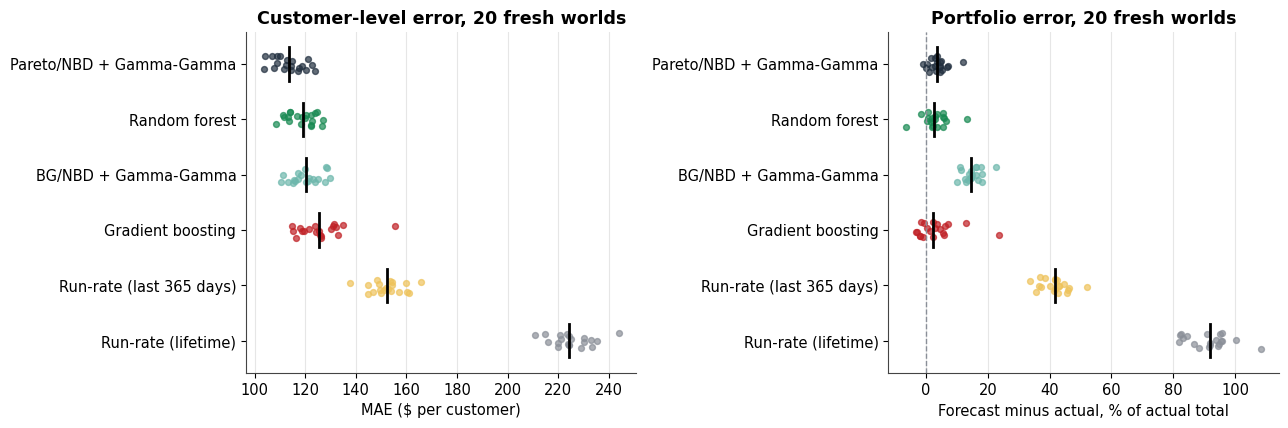

Each dot is one synthetic customer base; black bars mark the median.


In [20]:
if RUN_REPLICATION:
    rc = rep[rep.Target == '2025 contribution ($)'].copy()
    rc['MAE rank'] = rc.groupby('seed').MAE.rank()
    rc['abs portfolio error'] = rc['Signed portfolio error %'].abs()
    rc['Portfolio rank'] = rc.groupby('seed')['abs portfolio error'].rank()
    summary_rep = rc.groupby('model').agg(
        **{'MAE median': ('MAE', 'median'), 'MAE min': ('MAE', 'min'), 'MAE max': ('MAE', 'max'),
           'Seeds with lowest MAE': ('MAE rank', lambda r: int((r == 1).sum())),
           'Portfolio error % median': ('Signed portfolio error %', 'median'),
           'Portfolio error % min': ('Signed portfolio error %', 'min'),
           'Portfolio error % max': ('Signed portfolio error %', 'max'),
           'Median |portfolio error| %': ('abs portfolio error', 'median'),
           'Seeds with smallest |portfolio error|': ('Portfolio rank', lambda r: int((r == 1).sum()))})
    summary_rep.index = [LABEL[k] for k in summary_rep.index]
    summary_rep = summary_rep.sort_values('MAE median')
    print(f'Contribution forecasts across {rc.seed.nunique()} fresh synthetic customer bases:')
    display(summary_rep.round(2))
    summary_rep.to_csv(OUTPUT / 'replication_summary.csv')

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    order_r = [k for k in MODELS if LABEL[k] in summary_rep.index]
    order_r = sorted(order_r, key=lambda k: summary_rep.loc[LABEL[k], 'MAE median'])
    jitter = np.random.default_rng(0)
    for i, k in enumerate(order_r):
        d = rc[rc.model == k]
        for ax, col in zip(axes, ['MAE', 'Signed portfolio error %']):
            ax.scatter(d[col], i + jitter.uniform(-0.15, 0.15, len(d)), s=18, alpha=0.7, color=COLOR[k])
            ax.plot([d[col].median()] * 2, [i - 0.3, i + 0.3], color='black', lw=2)
    for ax in axes:
        ax.set_yticks(range(len(order_r))); ax.set_yticklabels([LABEL[k] for k in order_r]); ax.invert_yaxis()
        ax.grid(axis='y', visible=False)
    axes[0].set(xlabel='MAE ($ per customer)', title='Customer-level error, 20 fresh worlds')
    axes[1].axvline(0, color=GRAY, ls='--', lw=1)
    axes[1].set(xlabel='Forecast minus actual, % of actual total', title='Portfolio error, 20 fresh worlds')
    plt.tight_layout(); plt.savefig(OUTPUT / 'fig_replication.png', dpi=200); plt.show()
    print('Each dot is one synthetic customer base; black bars mark the median.')

## 14. Conclusions, limitations, and reproducibility

The cell below prints the key numbers so the conclusions stay tied to the actual output. Interpret the replication results (Section 13) first: they are the blind test.

**What the Version 6 run found.** On the primary seed, Pareto/NBD + Gamma-Gamma had the lowest customer-level MAE and landed within about 1% of total 2025 contribution, while BG/NBD + Gamma-Gamma overforecast by roughly 12%. Nearly all of BG/NBD's gap came from purchase occasions, not spend per occasion. In the blind replication, Pareto/NBD + Gamma-Gamma had the lowest MAE in 19 of 20 fresh worlds; random forest and gradient boosting were about as accurate on portfolio totals; BG/NBD consistently overforecast; and both run-rate baselines overforecast by roughly 40% to 90%. In the evaluation-only audit, Pareto/NBD's P(alive) separated truly active from lapsed customers far better than BG/NBD's. Confirm these statements against the printed summary below whenever the notebook is rerun.

**Points that hold regardless of which model ranks first:**

- **Naive run-rates overforecast** because they assume every customer is still buying. In a noncontractual business, silence is ambiguous, and handling that ambiguity is the whole point of predictive CLV.
- **Assumptions about dropout matter more than model sophistication.** BG/NBD and Pareto/NBD share everything except when a customer can drop out. In this simulator, where dropout can happen at any month-end, that one assumption drives most of the difference in their forecasts.
- **Check the numbers, then the model.** The NaN forecasts in earlier versions came from a numerical shortcut in a library, and the "fix" (heavy regularization) quietly biased the results.
- **ML and probabilistic models answer different questions well.** ML learned this customer base's one-year decay from 2024 and uses profile fields the probabilistic models ignore. The probabilistic models need no training labels, produce P(alive), and extend to multi-year, discounted lifetime value.

**Limitations:** synthetic data from one simulator design; one calendar holdout year per world; contribution after variable costs, not net profit; the 36-month projection is untested beyond 2025; purchase occasions (customer-days) are not the same unit as raw transactions; referral and advocacy value are not modeled; no causal claims.

**References:** Fader, Peter S., Bruce G. S. Hardie, and Ka Lok Lee. "'Counting Your Customers' the Easy Way: An Alternative to the Pareto/NBD Model." *Marketing Science*, vol. 24, no. 2, 2005, pp. 275-84. Fader, Peter S., Bruce G. S. Hardie, and Ka Lok Lee. "RFM and CLV: Using Iso-Value Curves for Customer Base Analysis." *Journal of Marketing Research*, vol. 42, no. 4, 2005, pp. 415-30. Schmittlein, David C., Donald G. Morrison, and Richard Colombo. "Counting Your Customers: Who Are They and What Will They Do Next?" *Management Science*, vol. 33, no. 1, 1987, pp. 1-24.

In [21]:
c = contrib_results.set_index('model')
print('PRIMARY SEED (not a blind test)')
for k in MODELS:
    print(f"  {LABEL[k]:28s} MAE ${c.loc[k, 'MAE']:7.2f} | portfolio error {c.loc[k, 'Signed portfolio error %']:+6.1f}%")
if RUN_REPLICATION:
    print(f'\nREPLICATION ({rc.seed.nunique()} fresh worlds, blind)')
    for name, r_ in summary_rep.iterrows():
        print(f"  {name:28s} median MAE ${r_['MAE median']:7.2f} | median portfolio error "
              f"{r_['Portfolio error % median']:+6.1f}% | lowest MAE in {int(r_['Seeds with lowest MAE']):2d} seeds | "
              f"closest total in {int(r_['Seeds with smallest |portfolio error|']):2d} seeds")

manifest = {'notebook_version': 'v6', 'primary_seed': SEED, 'calibration_end': str(CAL_END.date()),
            'holdout_end': str(HOLD_END.date()), 'ml_train_origin': str(ML_TRAIN_END.date()),
            'penalizers': {'bgnbd': BGNBD_PENALIZER, 'pareto_nbd': PARETO_PENALIZER, 'gamma_gamma': GG_PENALIZER},
            'bgnbd_expectation': 'direct evaluation of Fader-Hardie-Lee (2005) eq. 10 (no log of hyp2f1)',
            'pareto_expectation': 'P(alive) x conditional mean; P(alive)=1 limit when recency == T',
            'gamma_gamma_zero_repeat': 'model population mean p*v/(q-1) when q > 1',
            'same_day_transactions': 'aggregated to customer-day purchase occasions for probabilistic models',
            'convergence_handling': 'restart unpenalized fit from fixed starts [default, 0, 1, -1] on log scale',
            'replication_seeds': REPLICATION_SEEDS if RUN_REPLICATION else [],
            'holdout_used_for_tuning': False, 'primary_holdout_viewed_in_earlier_versions': True,
            'lifetimes_version': __import__('lifetimes').__version__, 'numpy_version': np.__version__,
            'pandas_version': pd.__version__}
(OUTPUT / 'experiment_manifest.json').write_text(json.dumps(manifest, indent=2))
preds.to_csv(OUTPUT / 'customer_predictions_2025.csv', index=False)
print('\nOutputs:', sorted(p.name for p in OUTPUT.iterdir()))
if Path('/content').exists():
    import shutil
    print('For download:', shutil.make_archive('/content/clv_model_results', 'zip', OUTPUT))

PRIMARY SEED (not a blind test)
  Run-rate (lifetime)          MAE $ 227.11 | portfolio error  +90.4%
  Run-rate (last 365 days)     MAE $ 153.76 | portfolio error  +40.7%
  BG/NBD + Gamma-Gamma         MAE $ 119.14 | portfolio error  +11.7%
  Pareto/NBD + Gamma-Gamma     MAE $ 113.83 | portfolio error   +1.0%
  Random forest                MAE $ 125.41 | portfolio error   +3.8%
  Gradient boosting            MAE $ 127.71 | portfolio error   +3.5%

REPLICATION (20 fresh worlds, blind)
  Pareto/NBD + Gamma-Gamma     median MAE $ 113.52 | median portfolio error   +3.5% | lowest MAE in 19 seeds | closest total in  8 seeds
  Random forest                median MAE $ 119.22 | median portfolio error   +2.6% | lowest MAE in  1 seeds | closest total in  5 seeds
  BG/NBD + Gamma-Gamma         median MAE $ 120.20 | median portfolio error  +14.7% | lowest MAE in  0 seeds | closest total in  0 seeds
  Gradient boosting            median MAE $ 125.48 | median portfolio error   +2.4% | lowest MAE in